# Part One : Numpy Intro
## 1-Vectors and matrices

In [1]:
import numpy as np

areas = [50, 70, 90, 110]
areas_np = np.array(areas)
print(areas_np * 2)

[100 140 180 220]


In [2]:
import numpy as np

# One dimensional array (Vector)
areas = np.array([50, 70, 90, 110])

# Two dimensional array (Matrics)
X = np.array([
    [50, 2],
    [70, 3],
    [90, 3],
    [110, 4]
])

print("Vector shape:", areas.shape)
print("Matrix shape:", X.shape)
print("Number of dimensions:", X.ndim)
print("Data type:", X.dtype)

Vector shape: (4,)
Matrix shape: (4, 2)
Number of dimensions: 2
Data type: int64


## 2-Slicing and Indexing

In [4]:
print(X[0])       
print(X[0, 1])    
print(X[:, 0])   
print(X[:, 1])    
print(X[:2, :])   

[50  2]
2
[ 50  70  90 110]
[2 3 3 4]
[[50  2]
 [70  3]]


In [25]:
houses = np.array([
    [80, 2, 10],
    [120, 3, 5],
    [150, 4, 2],
    [95, 2, 15],
    [200, 5, 1]
])                                             #feature1 is house area, feature2 is bedrooms numb, feature3 is house age
print(houses[:,2])                             #extracts the 3rd feature (house age)
print(houses[-2:,:])                           #extracts the last 2 houses
print(max(houses[:,0]))                        #finds the area of the largest house
print(houses[((houses[:,0]>100)==True)])       #selects houses with an area greater than 100 m^2
print(round((1/len(houses))*sum(houses[:,2]))) #calculates the avrg house age

[10  5  2 15  1]
[[ 95   2  15]
 [200   5   1]]
200
[[120   3   5]
 [150   4   2]
 [200   5   1]]
7


# Part Two : Vectorization and linear regression
## 1-Dot Product

In [26]:
x = np.array([100, 3])
w = np.array([2, 10])
b = 5

prediction = np.dot(x, w) + b

print("Predicted price:", prediction)

Predicted price: 235


## 2-Predict multiple houses

In [27]:
X = np.array([
    [50, 2],
    [70, 3],
    [90, 3],
    [110, 4]
])

w = np.array([2, 10])
b = 5

predictions = X @ w + b

print(predictions)

[125 175 215 265]


## Broadcasting

In [28]:
X = np.array([
    [50, 2],
    [70, 3],
    [90, 3]
])

offset = np.array([10, 1])

print(X + offset)

[[ 60   3]
 [ 80   4]
 [100   4]]


## Feature Scaling

In [29]:
X = np.array([
    [50, 2],
    [70, 3],
    [90, 3],
    [110, 4]
], dtype=float)

mu = X.mean(axis=0)
sigma = X.std(axis=0)

X_scaled = (X - mu) / sigma

print("Mean:", mu)
print("Standard deviation:", sigma)
print("Scaled features:\n", X_scaled)

Mean: [80.  3.]
Standard deviation: [22.36067977  0.70710678]
Scaled features:
 [[-1.34164079 -1.41421356]
 [-0.4472136   0.        ]
 [ 0.4472136   0.        ]
 [ 1.34164079  1.41421356]]


## Some implementations

In [30]:
def predict(X, w, b):  #func for prediction
    return ((X @ w) + b)
print(predict(X, w, b=3))

[123. 173. 213. 263.]


MSE = 1/m x SUM((Y(acctual)-Y(error))^2)

In [43]:
def mse(y_true, y_pred):        #func for MSE
    return (((1/len(y_true))*sum((y_true - y_pred)^2))) 
y_true =np.array([130,170,210,270])
y_false = np.array([123,173,213,263])
print(mse(y_true,y_false))

2.0


# Part Three: Working with Datasets
## DataFrame

In [44]:
import pandas as pd
import numpy as np

data = {
    "area": [50, 70, 90, 110, 130, 150, 170, 200],
    "bedrooms": [1, 2, 2, 3, 3, 4, 4, 5],
    "age": [20, 15, 10, 8, 5, 4, 2, 1],
    "price": [100, 145, 180, 230, 265, 310, 355, 420]
}

df = pd.DataFrame(data)

display(df)

,area,bedrooms,age,price
0,50,1,20,100
1,70,2,15,145
2,90,2,10,180
3,110,3,8,230
4,130,3,5,265
5,150,4,4,310
6,170,4,2,355
7,200,5,1,420


In [45]:
print(df["area"])

0     50
1     70
2     90
3    110
4    130
5    150
6    170
7    200
Name: area, dtype: int64


In [46]:
print(df[["area", "bedrooms"]])

   area  bedrooms
0    50         1
1    70         2
2    90         2
3   110         3
4   130         3
5   150         4
6   170         4
7   200         5


## Inspecting the Dataset

In [47]:
print(df.shape)
print(df.dtypes)

display(df.head())
display(df.describe())

print(df.isnull().sum())

(8, 4)
area        int64
bedrooms    int64
age         int64
price       int64
dtype: object


,area,bedrooms,age,price
0,50,1,20,100
1,70,2,15,145
2,90,2,10,180
3,110,3,8,230
4,130,3,5,265


,area,bedrooms,age,price
count,8.000000,8.000000,8.000000,8.00000
mean,121.250000,3.000000,8.125000,250.62500
std,51.112621,1.309307,6.621124,108.60931
min,50.000000,1.000000,1.000000,100.00000
25%,85.000000,2.000000,3.500000,171.25000
50%,120.000000,3.000000,6.500000,247.50000
75%,155.000000,4.000000,11.250000,321.25000
max,200.000000,5.000000,20.000000,420.00000


area        0
bedrooms    0
age         0
price       0
dtype: int64


## Filtering Data

In [48]:
large_houses = df[df["area"] > 100]

display(large_houses)

,area,bedrooms,age,price
3,110,3,8,230
4,130,3,5,265
5,150,4,4,310
6,170,4,2,355
7,200,5,1,420


In [49]:
selected = df[
    (df["area"] > 100) &
    (df["bedrooms"] >= 3)
]

display(selected)

,area,bedrooms,age,price
3,110,3,8,230
4,130,3,5,265
5,150,4,4,310
6,170,4,2,355
7,200,5,1,420


## Handeling missing values

In [50]:
df_dirty = df.copy()

df_dirty.loc[2, "area"] = np.nan
df_dirty.loc[5, "age"] = np.nan

display(df_dirty)

,area,bedrooms,age,price
0,50.0,1,20.0,100
1,70.0,2,15.0,145
2,NaN,2,10.0,180
3,110.0,3,8.0,230
4,130.0,3,5.0,265
5,150.0,4,NaN,310
6,170.0,4,2.0,355
7,200.0,5,1.0,420


In [51]:
print(df_dirty.isnull().sum())

area        1
bedrooms    0
age         1
price       0
dtype: int64


In [52]:
df_clean = df_dirty.copy()

df_clean["area"] = df_clean["area"].fillna(
    df_clean["area"].mean()
)

df_clean["age"] = df_clean["age"].fillna(
    df_clean["age"].mean()
)

display(df_clean)

,area,bedrooms,age,price
0,50.000000,1,20.000000,100
1,70.000000,2,15.000000,145
2,125.714286,2,10.000000,180
3,110.000000,3,8.000000,230
4,130.000000,3,5.000000,265
5,150.000000,4,8.714286,310
6,170.000000,4,2.000000,355
7,200.000000,5,1.000000,420


## Data Cleaning

In [53]:
df["price_per_m2"] = df["price"]/df["area"]
display(df["price_per_m2"])

0    2.000000
1    2.071429
2    2.000000
3    2.090909
4    2.038462
5    2.066667
6    2.088235
7    2.100000
Name: price_per_m2, dtype: float64

In [62]:
highest_hppm = df.index[df["price_per_m2"]== max(df["price_per_m2"])].tolist()
print(highest_hppm) #The house that has the highest price per square meter

[7]


In [70]:
avrg_al3br = df[df["bedrooms"]>= 3]["price"].mean()
print(avrg_al3br) #the average price of houses with at least three bedrooms

316.0


In [72]:
older_than_10_count = (df['age'] > 10).sum()
print(older_than_10_count) # houses that are older than 10 years

2


In [74]:
area_price_correlation = df['area'].corr(df['price'])
print(area_price_correlation) # the correlation between area and price

0.9996038209490958


In [76]:
sorted_df = df.sort_values(by='price', ascending=False)
display(sorted_df) # sorted dataset by price in descending order

,area,bedrooms,age,price,price_per_m2
7,200,5,1,420,2.100000
6,170,4,2,355,2.088235
5,150,4,4,310,2.066667
4,130,3,5,265,2.038462
3,110,3,8,230,2.090909
2,90,2,10,180,2.000000
1,70,2,15,145,2.071429
0,50,1,20,100,2.000000


# Part Four : Matplotlib : Visualizing patterns
## 1-Scatter plots

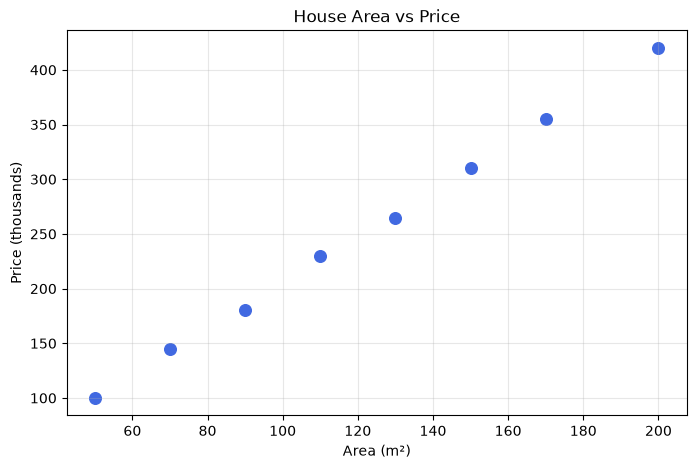

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["area"],
    df["price"],
    color="royalblue",
    s=70
)

plt.xlabel("Area (m²)")
plt.ylabel("Price (thousands)")
plt.title("House Area vs Price")
plt.grid(alpha=0.3)

plt.show()

# 2-Histograms

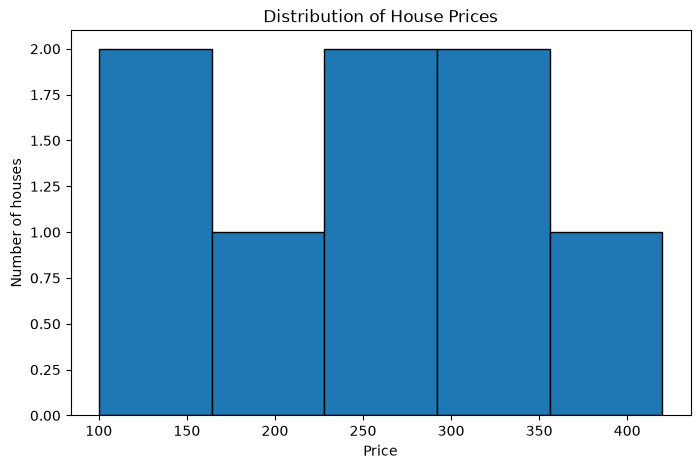

In [78]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["price"],
    bins=5,
    edgecolor="black"
)

plt.xlabel("Price")
plt.ylabel("Number of houses")
plt.title("Distribution of House Prices")

plt.show()

# 3-Correlation heatmaps

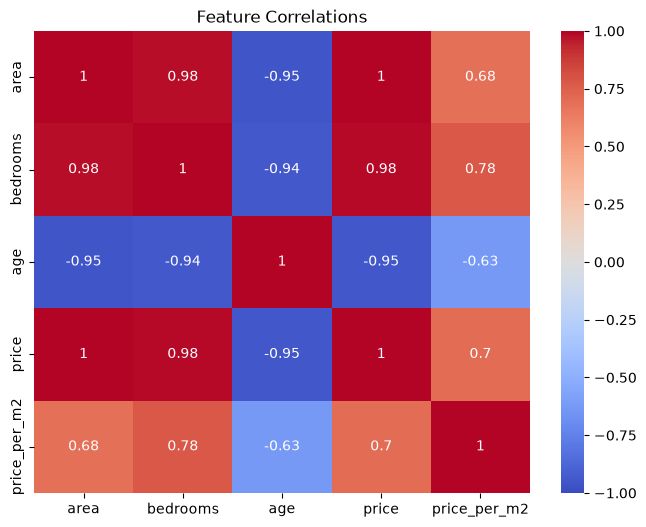

In [79]:
import seaborn as sns

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlations")
plt.show()

# Part Five :Engineering experiment
## step 1 : Generating the Dataset

In [80]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

n = 200

area = rng.integers(40, 250, n)
bedrooms = rng.integers(1, 6, n)
age = rng.integers(0, 40, n)

noise = rng.normal(0, 20, n)

price = (
    2.5 * area
    + 12 * bedrooms
    - 1.5 * age
    + 30
    + noise
)

housing = pd.DataFrame({
    "area": area,
    "bedrooms": bedrooms,
    "age": age,
    "price": price
})

housing.to_csv("housing_lab01.csv", index=False)

display(housing.head())

,area,bedrooms,age,price
0,58,2,39,134.656576
1,202,5,31,546.430235
2,177,3,12,485.460452
3,132,4,38,354.051250
4,130,3,19,391.929839
